## The purpose of this notebook is:

"Can we build a better model than Linear Regression?"

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [3]:
df = pd.read_csv("../data/final_uber_dataset.csv")

In [4]:
X = df.drop('fare_amount', axis=1)

Y = df['fare_amount']

In [5]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

In [6]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [9]:
rf_model.fit(X_train, Y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [10]:
rf_pred = rf_model.predict(X_test)

In [11]:
mae = mean_absolute_error(Y_test, rf_pred)

mse = mean_squared_error(Y_test, rf_pred)

rmse = np.sqrt(mse)

r2 = r2_score(Y_test, rf_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE : 2.020869123052234
MSE : 20.474380946419995
RMSE: 4.524862533427949
R2 Score: 0.7921574801811719


In [12]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [0.7282, 0.79]
})

comparison

,Model,R2 Score
0,Linear Regression,0.7282
1,Random Forest,0.7900


In [13]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance.sort_values(
    by='Importance',
    ascending=False
)

,Feature,Importance
5,distance_km,0.805000
2,dropoff_longitude,0.053271
0,pickup_longitude,0.034469
3,dropoff_latitude,0.031584
1,pickup_latitude,0.025196
6,hour,0.014859
7,day,0.013824
8,month,0.009894
9,weekday,0.007783
4,passenger_count,0.004119


In [14]:
import joblib

joblib.dump(rf_model, "../models/final_model.pkl")

['../models/final_model.pkl']

Random Forest outperformed Linear Regression.

Linear Regression R² Score = 0.728
Random Forest R² Score = 0.79

Distance was identified as the most important feature,
contributing approximately 80.5% of the model's predictive power.

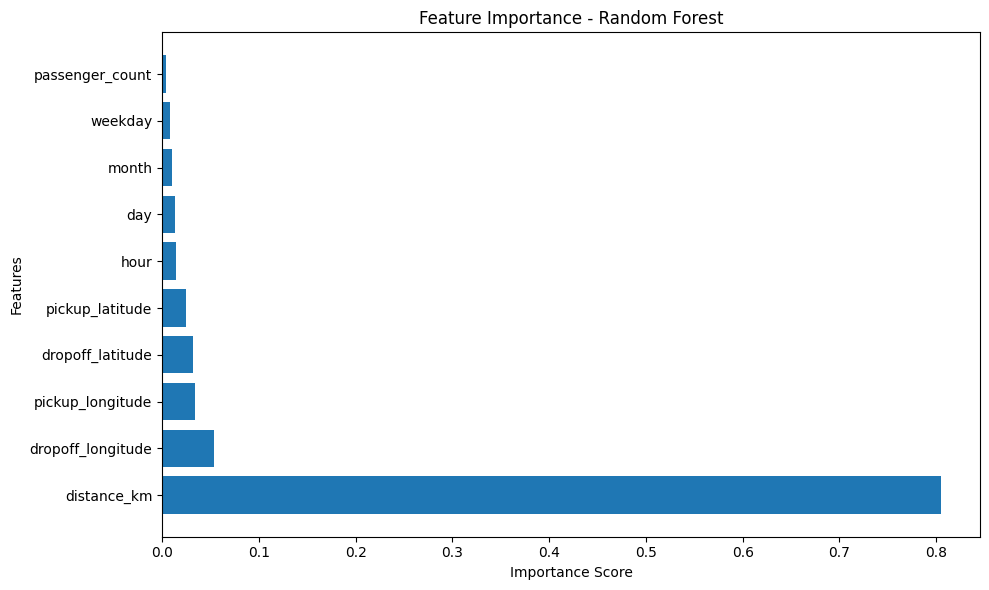

In [15]:
import matplotlib.pyplot as plt

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(10,6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Feature Importance - Random Forest")

plt.tight_layout()

plt.show()

In [16]:
plt.savefig(
    "feature_importance.jpg",
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

In [17]:

import os
import time
import joblib
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
baseline_pred = rf_model.predict(X_test)

print("Original model")
print("MAE:", mean_absolute_error(Y_test, baseline_pred))
print("RMSE:", np.sqrt(mean_squared_error(Y_test, baseline_pred)))
print("R2:", r2_score(Y_test, baseline_pred))

# Train a smaller candidate
small_rf = RandomForestRegressor(
    n_estimators=30,
    max_depth=20,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

start = time.time()
small_rf.fit(X_train, Y_train)
print(f"\nTraining time: {time.time() - start:.1f} seconds")

# Compare predictive quality
small_pred = small_rf.predict(X_test)

print("\nSmaller model")
print("MAE:", mean_absolute_error(Y_test, small_pred))
print("RMSE:", np.sqrt(mean_squared_error(Y_test, small_pred)))
print("R2:", r2_score(Y_test, small_pred))

# Save candidate separately; do not overwrite the original
candidate_path = "../models/final_model_candidate.pkl"
joblib.dump(small_rf, candidate_path, compress=3)

print(
    "\nCandidate file size:",
    round(os.path.getsize(candidate_path) / (1024 ** 2), 2),
    "MB"
)


Original model
MAE: 2.020869123052234
RMSE: 4.524862533427949
R2: 0.7921574801811719

Training time: 14.7 seconds

Smaller model
MAE: 2.0006789339404194
RMSE: 4.493007039452755
R2: 0.7950736439723658

Candidate file size: 10.96 MB
